In [1]:
import os
import sys
from pathlib import Path

ROOT_DIR = Path("/content/pcv-aco-ag")
if not ROOT_DIR.exists():
    !git clone -b hellyel-ant-q https://github.com/estudosunisantos/pcv-aco-ag.git {ROOT_DIR}

os.chdir(ROOT_DIR)
for p in (str(ROOT_DIR), str(ROOT_DIR / "pcv")):
    if p not in sys.path:
        sys.path.insert(0, p)

!python3 -m pcv.recalcular_matriz
!PYTHONPATH=.:pcv python3 -m unittest discover -s tests

Matriz confere numericamente com as coordenadas (tolerância: 1e-9 km).
..
----------------------------------------------------------------------
Ran 2 tests in 0.017s

OK


In [2]:
import json
import time
import typing as tp
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from pcv.base import carregar, avaliar_rota

CIDADES: tp.Final[int] = 20
AGENTES: tp.Final[int] = CIDADES

# Constantes do Ant-Q (Gambardella & Dorigo, 1995/1996)
DELTA: tp.Final[float] = 1.0
BETA: tp.Final[float] = 2.0
Q0: tp.Final[float] = 0.9
ALPHA: tp.Final[float] = 0.1
GAMMA: tp.Final[float] = 0.4
W: tp.Final[float] = 10.0
ITERACOES: tp.Final[int] = 500
SEED: tp.Final[int] = 42

matriz_lista, MATRIZ_SHA256 = carregar(CIDADES)

municipios = json.loads(
    Path("dados/municipios-prefeituras.json").read_text(encoding="utf-8")
)[:CIDADES]
mapa_cidades = np.array([[m["longitude"], m["latitude"]] for m in municipios], dtype=float)

# Inicializacao AQ_0 = 1 / (distancia_media * n)
media_arestas = sum(sum(linha) for linha in matriz_lista) / (CIDADES * (CIDADES - 1))
AQ_0 = 1.0 / (media_arestas * CIDADES)

print(f"Instancia carregada: {CIDADES} municipios | SHA-256: {MATRIZ_SHA256}")
print(f"Distancia media das arestas: {media_arestas:.4f} km | AQ_0: {AQ_0:.6f}")

Instancia carregada: 20 municipios | SHA-256: caaecf3f24f62b7f3bec30242b9c546dc94a9638eae41e49047e82b858ecaa5e
Distancia media das arestas: 6.7860 km | AQ_0: 0.007368


In [3]:
import random

# Pre-calcula a heuristica (1 / d)^BETA em lista nativa (evita recalculo e overhead NumPy)
he_beta = [
    [0.0 if i == j else (1.0 / matriz_lista[i][j]) ** BETA for j in range(CIDADES)]
    for i in range(CIDADES)
]

# Q-table em lista nativa para acesso O(1) rapido no loop interno
aq_valores = [[0.0 if i == j else AQ_0 for j in range(CIDADES)] for i in range(CIDADES)]
tours_lista = [[-1] * (CIDADES + 1) for _ in range(AGENTES)]
custos_lista = [0.0] * AGENTES


def prox_cidade(_atual: int, nao_visitadas_f: set[int], rng: random.Random) -> int:
    row_aq = aq_valores[_atual]
    row_he = he_beta[_atual]

    # Com probabilidade Q0 faz explotacao (argmax)
    if rng.random() <= Q0:
        melhor_c = -1
        melhor_val = -1.0
        for c in nao_visitadas_f:
            val = (row_aq[c] ** DELTA) * row_he[c]
            if val > melhor_val:
                melhor_val = val
                melhor_c = c
        return melhor_c

    # Caso contrario faz exploracao (roleta proporcional)
    candidatos = list(nao_visitadas_f)
    pesos = [(row_aq[c] ** DELTA) * row_he[c] for c in candidatos]
    soma = sum(pesos)
    if soma <= 0.0:
        return rng.choice(candidatos)

    alvo = rng.random() * soma
    acum = 0.0
    for c, p in zip(candidatos, pesos):
        acum += p
        if acum >= alvo:
            return c
    return candidatos[-1]


def atualiza_aq_local(
    r: int, s: int, nao_visitadas_f: set[int], cidade_inicial: int, passo: int
) -> None:
    if passo < CIDADES - 1:
        row_s = aq_valores[s]
        max_prox = max(row_s[z] for z in nao_visitadas_f)
    elif passo == CIDADES - 1:
        max_prox = aq_valores[s][cidade_inicial]
    else:
        max_prox = 0.0

    novo_aq = (1.0 - ALPHA) * aq_valores[r][s] + ALPHA * GAMMA * max_prox
    aq_valores[r][s] = novo_aq
    aq_valores[s][r] = novo_aq


def custos_tours() -> int:
    global melhor_agente
    melhor_custo = float("inf")
    melhor_agente = 0

    for f in range(AGENTES):
        tour_f = tours_lista[f]
        total = 0.0
        for a in range(CIDADES):
            total += matriz_lista[tour_f[a]][tour_f[a + 1]]
        custos_lista[f] = total
        if total < melhor_custo:
            melhor_custo = total
            melhor_agente = f

    return melhor_agente


def atualiza_aq_global(agente_reforco: int) -> None:
    delta_aq = W / custos_lista[agente_reforco]
    tour_melhor = tours_lista[agente_reforco]

    for m in range(CIDADES):
        u = tour_melhor[m]
        v = tour_melhor[m + 1]
        novo_aq = (1.0 - ALPHA) * aq_valores[u][v] + ALPHA * delta_aq
        aq_valores[u][v] = novo_aq
        aq_valores[v][u] = novo_aq


def tour_para_ids_oficiais(tour_idx: list[int]) -> list[int]:
    ciclo = list(tour_idx[:-1])
    pos_zero = ciclo.index(0)
    rotacionado = ciclo[pos_zero:] + ciclo[:pos_zero]
    return [c + 1 for c in rotacionado] + [1]

Tempo de execucao   : 1.7458 s
Melhor custo oficial: 47.624003 km (encontrado na iteracao 20)
Melhor rota (IDs)   : [1, 3, 8, 16, 12, 15, 14, 10, 13, 18, 11, 9, 20, 19, 17, 5, 7, 2, 6, 4, 1]


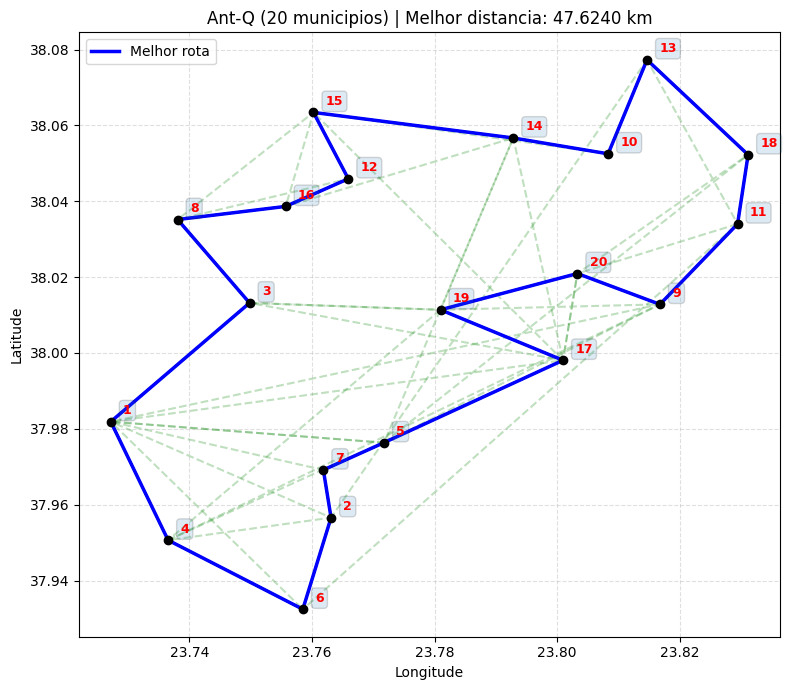

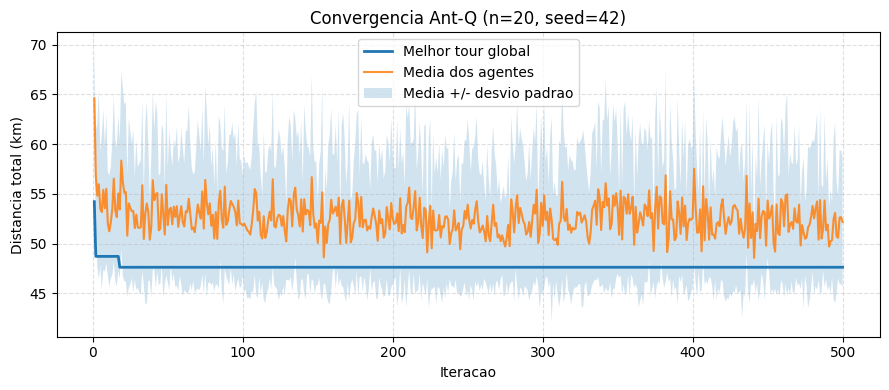

In [4]:
def plotar_mapa_rotas(
    melhor_tour: list[int],
    todas_rotas: list[list[int]],
    titulo: str,
    mostrar_todas: bool = True,
) -> None:
    plt.figure(figsize=(8, 7))

    if mostrar_todas:
        for rota_f in todas_rotas:
            coords = mapa_cidades[rota_f]
            plt.plot(coords[:, 0], coords[:, 1], linestyle="dashed", color="green", alpha=0.25)

    coords_melhor = mapa_cidades[melhor_tour]
    plt.plot(coords_melhor[:, 0], coords_melhor[:, 1], color="blue", linewidth=2.5, label="Melhor rota")
    plt.scatter(mapa_cidades[:, 0], mapa_cidades[:, 1], color="black", zorder=5)

    for idx in range(CIDADES):
        lon, lat = mapa_cidades[idx]
        plt.annotate(
            str(idx + 1),
            (lon, lat),
            xytext=(lon + 0.002, lat + 0.002),
            bbox=dict(boxstyle="round", alpha=0.15),
            color="red",
            size=9,
            fontweight="bold",
        )

    plt.title(titulo)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.legend()
    plt.tight_layout()
    plt.show()


rng = random.Random(SEED)
inicio_lista = list(range(CIDADES))

# Reinicia a Q-table em lista nativa (compativel com a Celula 3)
aq_valores = [[0.0 if i == j else AQ_0 for j in range(CIDADES)] for i in range(CIDADES)]

melhor_global_custo = float("inf")
melhor_global_tour: list[int] = []
iteracao_melhor = -1

hist_melhor_global = []
hist_media_agentes = []
hist_std_agentes = []

t0 = time.perf_counter()

for it in range(1, ITERACOES + 1):
    rng.shuffle(inicio_lista)
    nao_visitadas = []

    for f in range(AGENTES):
        c0 = inicio_lista[f % CIDADES]
        tours_lista[f][0] = c0
        restantes = set(range(CIDADES))
        restantes.remove(c0)
        nao_visitadas.append(restantes)

    # Construcao sincrona (passo a passo) + atualizacao local (Q-learning)
    for t in range(1, CIDADES + 1):
        for f in range(AGENTES):
            atual = tours_lista[f][t - 1]
            if t < CIDADES:
                prox = prox_cidade(atual, nao_visitadas[f], rng)
                nao_visitadas[f].remove(prox)
                tours_lista[f][t] = prox
            else:
                tours_lista[f][t] = tours_lista[f][0]

        for f in range(AGENTES):
            atualiza_aq_local(
                tours_lista[f][t - 1],
                tours_lista[f][t],
                nao_visitadas[f],
                tours_lista[f][0],
                t,
            )

    idx_best = custos_tours()
    if custos_lista[idx_best] < melhor_global_custo:
        melhor_global_custo = custos_lista[idx_best]
        melhor_global_tour = list(tours_lista[idx_best])
        iteracao_melhor = it

    atualiza_aq_global(idx_best)

    hist_melhor_global.append(melhor_global_custo)
    hist_media_agentes.append(float(np.mean(custos_lista)))
    hist_std_agentes.append(float(np.std(custos_lista)))

tempo_execucao = time.perf_counter() - t0

rota_oficial_ids = tour_para_ids_oficiais(melhor_global_tour)
custo_oficial = avaliar_rota(matriz_lista, rota_oficial_ids)

print(f"Tempo de execucao   : {tempo_execucao:.4f} s")
print(f"Melhor custo oficial: {custo_oficial:.6f} km (encontrado na iteracao {iteracao_melhor})")
print(f"Melhor rota (IDs)   : {rota_oficial_ids}")

# Grafico 1 è um Mapa geografico da melhor rota
plotar_mapa_rotas(
    melhor_global_tour,
    tours_lista,
    f"Ant-Q ({CIDADES} municipios) | Melhor distancia: {custo_oficial:.4f} km",
    mostrar_todas=True,
)

# Grafico 2 é a Curva de convergencia
iters = np.arange(1, ITERACOES + 1)
media_arr = np.array(hist_media_agentes)
std_arr = np.array(hist_std_agentes)

plt.figure(figsize=(9, 4))
plt.plot(iters, hist_melhor_global, label="Melhor tour global", linewidth=2)
plt.plot(iters, media_arr, label="Media dos agentes", alpha=0.85)
plt.fill_between(iters, media_arr - std_arr, media_arr + std_arr, alpha=0.2, label="Media +/- desvio padrao")
plt.title(f"Convergencia Ant-Q (n={CIDADES}, seed={SEED})")
plt.xlabel("Iteracao")
plt.ylabel("Distancia total (km)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [5]:
import platform

N_EXECUCOES = 30
custos_sementes = []
tempos_sementes = []
melhor_geral_custo = float("inf")
melhor_geral_rota = None
melhor_geral_seed = None
melhor_geral_tempo = 0.0

inicio_lista = list(range(CIDADES))
t_total_0 = time.perf_counter()

for seed_i in range(1, N_EXECUCOES + 1):
    rng_i = random.Random(seed_i)
    aq_valores = [[0.0 if i == j else AQ_0 for j in range(CIDADES)] for i in range(CIDADES)]

    best_custo_i = float("inf")
    best_tour_i = None
    t_ini = time.perf_counter()

    for _ in range(ITERACOES):
        rng_i.shuffle(inicio_lista)
        nao_visitadas = []

        for f in range(AGENTES):
            c0 = inicio_lista[f % CIDADES]
            tours_lista[f][0] = c0
            restantes = set(range(CIDADES))
            restantes.remove(c0)
            nao_visitadas.append(restantes)

        for t in range(1, CIDADES + 1):
            for f in range(AGENTES):
                atual = tours_lista[f][t - 1]
                if t < CIDADES:
                    prox = prox_cidade(atual, nao_visitadas[f], rng_i)
                    nao_visitadas[f].remove(prox)
                    tours_lista[f][t] = prox
                else:
                    tours_lista[f][t] = tours_lista[f][0]

            for f in range(AGENTES):
                atualiza_aq_local(
                    tours_lista[f][t - 1],
                    tours_lista[f][t],
                    nao_visitadas[f],
                    tours_lista[f][0],
                    t,
                )

        idx_best = custos_tours()
        if custos_lista[idx_best] < best_custo_i:
            best_custo_i = custos_lista[idx_best]
            best_tour_i = list(tours_lista[idx_best])
        atualiza_aq_global(idx_best)

    dt = time.perf_counter() - t_ini
    rota_ids_i = tour_para_ids_oficiais(best_tour_i)
    custo_val_i = avaliar_rota(matriz_lista, rota_ids_i)

    custos_sementes.append(custo_val_i)
    tempos_sementes.append(dt)

    if custo_val_i < melhor_geral_custo:
        melhor_geral_custo = custo_val_i
        melhor_geral_rota = rota_ids_i
        melhor_geral_seed = seed_i
        melhor_geral_tempo = dt

    if seed_i % 5 == 0 or seed_i == 1:
        print(f"Seed {seed_i:02d}/{N_EXECUCOES} | custo={custo_val_i:.4f} km | tempo={dt:.3f} s")

print(f"\nTempo total das {N_EXECUCOES} sementes: {time.perf_counter() - t_total_0:.2f} s")
print(f"=== Estatisticas Ant-Q ({N_EXECUCOES} sementes, {ITERACOES} iteracoes, n={CIDADES}) ===")
print(f"Melhor distancia (km): {np.min(custos_sementes):.6f} (seed={melhor_geral_seed})")
print(f"Media (km)           : {np.mean(custos_sementes):.6f}")
print(f"Desvio padrao (km)   : {np.std(custos_sementes, ddof=1):.6f}")
print(f"Pior distancia (km)  : {np.max(custos_sementes):.6f}")
print(f"Tempo medio (s)      : {np.mean(tempos_sementes):.4f}")
print(f"Melhor rota (IDs)    : {melhor_geral_rota}")

mapa_nomes_por_id = {m["id"]: m["municipio"] for m in municipios}

resultado_json = {
    "algoritmo": "Ant-Q",
    "n": CIDADES,
    "matriz_sha256": MATRIZ_SHA256,
    "rota_ids": melhor_geral_rota,
    "distancia_km": melhor_geral_custo,
    "tempo_segundos": melhor_geral_tempo,
    "semente": melhor_geral_seed,
    "parametros": {
        "iteracoes": ITERACOES,
        "agentes": AGENTES,
        "delta": DELTA,
        "beta": BETA,
        "q0": Q0,
        "alpha": ALPHA,
        "gamma": GAMMA,
        "W": W,
        "reforco": "iteration-best",
        "execucoes_estatisticas": N_EXECUCOES,
        "media_distancia_km": float(np.mean(custos_sementes)),
        "desvio_padrao_km": float(np.std(custos_sementes, ddof=1)),
        "tempo_medio_segundos": float(np.mean(tempos_sementes)),
    },
    "ambiente": {
        "sistema": platform.platform(),
        "python": platform.python_version(),
        "processador": platform.processor() or platform.machine(),
    },
    "rota_municipios": [mapa_nomes_por_id[i] for i in melhor_geral_rota],
}

caminho_saida = Path(f"resultados/ant_q_{CIDADES}_prefeituras.json")
caminho_saida.write_text(
    json.dumps(resultado_json, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(f"\nResultado salvo em: {caminho_saida}")
!PYTHONPATH=.:pcv python3 -m pcv.validar_resultado {caminho_saida}

Seed 01/30 | custo=47.6240 km | tempo=2.203 s
Seed 05/30 | custo=47.6240 km | tempo=1.118 s
Seed 10/30 | custo=47.6240 km | tempo=0.846 s
Seed 15/30 | custo=47.6240 km | tempo=0.850 s
Seed 20/30 | custo=47.6240 km | tempo=0.859 s
Seed 25/30 | custo=47.6240 km | tempo=0.852 s
Seed 30/30 | custo=47.6240 km | tempo=1.098 s

Tempo total das 30 sementes: 31.67 s
=== Estatisticas Ant-Q (30 sementes, 500 iteracoes, n=20) ===
Melhor distancia (km): 47.624003 (seed=1)
Media (km)           : 47.624003
Desvio padrao (km)   : 0.000000
Pior distancia (km)  : 47.624003
Tempo medio (s)      : 1.0556
Melhor rota (IDs)    : [1, 3, 8, 16, 12, 15, 14, 10, 13, 18, 11, 9, 20, 19, 17, 5, 7, 2, 6, 4, 1]

Resultado salvo em: resultados/ant_q_20_prefeituras.json
{
  "valido": true,
  "distancia_recalculada_km": 47.62400341786233,
  "observacao": "Formato e custo válidos; a otimalidade não foi verificada."
}


In [6]:
%%writefile /content/pcv-aco-ag/pcv/ant_q.py
from __future__ import annotations

import argparse
import json
import platform
import random
import statistics
import time
from pathlib import Path

from pcv.base import avaliar_rota, carregar

ROOT = Path(__file__).resolve().parent.parent


def normalizar_rota_ids(tour_idx: list[int]) -> list[int]:
    ciclo = list(tour_idx[:-1])
    pos_zero = ciclo.index(0)
    rotacionado = ciclo[pos_zero:] + ciclo[:pos_zero]
    return [c + 1 for c in rotacionado] + [1]


def executar_ant_q(
    matriz: list[list[float]],
    iteracoes: int = 500,
    agentes: int | None = None,
    delta: float = 1.0,
    beta: float = 2.0,
    q0: float = 0.9,
    alpha: float = 0.1,
    gamma: float = 0.4,
    w: float = 10.0,
    seed: int = 42,
) -> dict:
    t0 = time.perf_counter()
    rng = random.Random(seed)
    n = len(matriz)
    m = n if agentes is None else agentes

    he_beta = [
        [0.0 if i == j else (1.0 / matriz[i][j]) ** beta for j in range(n)]
        for i in range(n)
    ]

    media_arestas = sum(
        matriz[i][j] for i in range(n) for j in range(n) if i != j
    ) / (n * (n - 1))
    aq0 = 1.0 / (media_arestas * n)
    aq = [[0.0 if i == j else aq0 for j in range(n)] for i in range(n)]

    inicio = list(range(n))
    tours = [[-1] * (n + 1) for _ in range(m)]
    custos = [0.0] * m

    melhor_global_custo = float("inf")
    melhor_global_tour: list[int] = []
    iteracao_melhor = -1

    for it in range(1, iteracoes + 1):
        rng.shuffle(inicio)
        nao_visitadas: list[set[int]] = []

        for f in range(m):
            c0 = inicio[f % n]
            tours[f][0] = c0
            restantes = set(range(n))
            restantes.remove(c0)
            nao_visitadas.append(restantes)

        # Construcao sincrona (passo a passo) + atualizacao local (Q-learning)
        for t in range(1, n + 1):
            for f in range(m):
                atual = tours[f][t - 1]
                if t < n:
                    row_aq = aq[atual]
                    row_he = he_beta[atual]
                    if rng.random() <= q0:
                        melhor_c = -1
                        melhor_val = -1.0
                        for c in nao_visitadas[f]:
                            val = (row_aq[c] ** delta) * row_he[c]
                            if val > melhor_val:
                                melhor_val = val
                                melhor_c = c
                        prox = melhor_c
                    else:
                        candidatos = list(nao_visitadas[f])
                        pesos = [(row_aq[c] ** delta) * row_he[c] for c in candidatos]
                        soma = sum(pesos)
                        if soma <= 0.0:
                            prox = rng.choice(candidatos)
                        else:
                            alvo = rng.random() * soma
                            acum = 0.0
                            prox = candidatos[-1]
                            for c, p in zip(candidatos, pesos):
                                acum += p
                                if acum >= alvo:
                                    prox = c
                                    break
                    nao_visitadas[f].remove(prox)
                    tours[f][t] = prox
                else:
                    tours[f][t] = tours[f][0]

            for f in range(m):
                r = tours[f][t - 1]
                s = tours[f][t]
                if t < n - 1:
                    row_s = aq[s]
                    max_prox = max(row_s[z] for z in nao_visitadas[f])
                elif t == n - 1:
                    max_prox = aq[s][tours[f][0]]
                else:
                    max_prox = 0.0

                novo_aq = (1.0 - alpha) * aq[r][s] + alpha * gamma * max_prox
                aq[r][s] = novo_aq
                aq[s][r] = novo_aq

        # Avaliacao dos tours
        idx_best = 0
        custo_best_it = float("inf")
        for f in range(m):
            tf = tours[f]
            total = 0.0
            for a in range(n):
                total += matriz[tf[a]][tf[a + 1]]
            custos[f] = total
            if total < custo_best_it:
                custo_best_it = total
                idx_best = f

        if custo_best_it < melhor_global_custo:
            melhor_global_custo = custo_best_it
            melhor_global_tour = list(tours[idx_best])
            iteracao_melhor = it

        # Reforco global atrasado (iteration-best)
        delta_aq = w / custo_best_it
        tour_best = tours[idx_best]
        for a in range(n):
            u = tour_best[a]
            v = tour_best[a + 1]
            novo_aq = (1.0 - alpha) * aq[u][v] + alpha * delta_aq
            aq[u][v] = novo_aq
            aq[v][u] = novo_aq

    tempo_segundos = time.perf_counter() - t0
    rota_ids = normalizar_rota_ids(melhor_global_tour)
    distancia_km = avaliar_rota(matriz, rota_ids)

    return {
        "rota_ids": rota_ids,
        "distancia_km": distancia_km,
        "tempo_segundos": tempo_segundos,
        "iteracao_melhor": iteracao_melhor,
        "seed": seed,
    }


def main() -> None:
    parser = argparse.ArgumentParser(description="Executa Ant-Q no PCV de Atenas.")
    parser.add_argument("--n", type=int, default=20, help="Numero de municipios (3..20).")
    parser.add_argument("--iteracoes", type=int, default=500)
    parser.add_argument("--sementes", type=int, default=30, help="Quantidade de execucoes (seeds 1..k).")
    parser.add_argument("--delta", type=float, default=1.0)
    parser.add_argument("--beta", type=float, default=2.0)
    parser.add_argument("--q0", type=float, default=0.9)
    parser.add_argument("--alpha", type=float, default=0.1)
    parser.add_argument("--gamma", type=float, default=0.4)
    parser.add_argument("--W", type=float, default=10.0)
    parser.add_argument("--saida", type=Path, default=None)
    args = parser.parse_args()

    matriz, sha256 = carregar(args.n)
    municipios = json.loads(
        (ROOT / "dados/municipios-prefeituras.json").read_text(encoding="utf-8")
    )[: args.n]
    mapa_nomes = {item["id"]: item["municipio"] for item in municipios}

    execucoes = [
        executar_ant_q(
            matriz,
            iteracoes=args.iteracoes,
            delta=args.delta,
            beta=args.beta,
            q0=args.q0,
            alpha=args.alpha,
            gamma=args.gamma,
            w=args.W,
            seed=s,
        )
        for s in range(1, args.sementes + 1)
    ]

    melhor = min(execucoes, key=lambda r: r["distancia_km"])
    distancias = [r["distancia_km"] for r in execucoes]
    tempos = [r["tempo_segundos"] for r in execucoes]

    payload = {
        "algoritmo": "Ant-Q",
        "n": args.n,
        "matriz_sha256": sha256,
        "rota_ids": melhor["rota_ids"],
        "distancia_km": melhor["distancia_km"],
        "tempo_segundos": melhor["tempo_segundos"],
        "semente": melhor["seed"],
        "parametros": {
            "iteracoes": args.iteracoes,
            "agentes": args.n,
            "delta": args.delta,
            "beta": args.beta,
            "q0": args.q0,
            "alpha": args.alpha,
            "gamma": args.gamma,
            "W": args.W,
            "reforco": "iteration-best",
            "execucoes_estatisticas": args.sementes,
            "media_distancia_km": statistics.mean(distancias),
            "desvio_padrao_km": statistics.stdev(distancias) if len(distancias) > 1 else 0.0,
            "pior_distancia_km": max(distancias),
            "tempo_medio_segundos": statistics.mean(tempos),
        },
        "ambiente": {
            "sistema": platform.platform(),
            "python": platform.python_version(),
            "processador": platform.processor() or platform.machine(),
        },
        "rota_municipios": [mapa_nomes[i] for i in melhor["rota_ids"]],
    }

    destino = args.saida or (ROOT / f"resultados/ant_q_{args.n}_prefeituras.json")
    destino.parent.mkdir(parents=True, exist_ok=True)
    destino.write_text(json.dumps(payload, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

    print(f"n={args.n} | melhor={melhor['distancia_km']:.6f} km (seed={melhor['seed']}, iter={melhor['iteracao_melhor']})")
    print(f"media={payload['parametros']['media_distancia_km']:.6f} km | std={payload['parametros']['desvio_padrao_km']:.6f} km")
    print(f"tempo medio={payload['parametros']['tempo_medio_segundos']:.4f} s | salvo em: {destino}")


if __name__ == "__main__":
    main()

Overwriting /content/pcv-aco-ag/pcv/ant_q.py


In [7]:
!python3 -m pcv.ant_q --n 10 --sementes 30 --saida resultados/ant_q_10_prefeituras.json
!PYTHONPATH=.:pcv python3 -m pcv.validar_resultado resultados/ant_q_10_prefeituras.json

!python3 -m pcv.ant_q --n 20 --sementes 30 --saida resultados/ant_q_20_prefeituras.json
!PYTHONPATH=.:pcv python3 -m pcv.validar_resultado resultados/ant_q_20_prefeituras.json

n=10 | melhor=34.901908 km (seed=1, iter=3)
media=34.901908 km | std=0.000000 km
tempo medio=0.1447 s | salvo em: resultados/ant_q_10_prefeituras.json
{
  "valido": true,
  "distancia_recalculada_km": 34.90190792262401,
  "observacao": "Formato e custo válidos; a otimalidade não foi verificada."
}
n=20 | melhor=47.624003 km (seed=1, iter=3)
media=47.624003 km | std=0.000000 km
tempo medio=0.7368 s | salvo em: resultados/ant_q_20_prefeituras.json
{
  "valido": true,
  "distancia_recalculada_km": 47.62400341786233,
  "observacao": "Formato e custo válidos; a otimalidade não foi verificada."
}
